# Projeto final IN1165 — Advanced ML & Explainable AI (CIn/UFPE)

**Previsão de alagamento em pontos críticos do Recife, com explicação e avaliação das explicações.**

> **DADOS SINTÉTICOS — experimento controlado.** As features são horas reais (chuva medida pelo Cemaden, chuva de
> reanálise, maré prevista); o **rótulo** é gerado por uma fórmula conhecida, porque não há registro real de alagamento
> suficiente (seção 1). Nenhum número deste notebook é desempenho em alagamento real.

O notebook roda do início ao fim chamando os módulos de `mapi_ai/`, na ordem: dataset → treino → baselines → métricas →
calibração → SHAP → LIME → contrafactual → avaliação das explicações. Cada passo regrava a sua parte de `reports/`.

DADOS DA REDE OBSERVACIONAL DO CEMADEN/MCTIC

In [1]:
import os, sys, json
from pathlib import Path
# O notebook mora em notebooks/; os módulos ficam na raiz do repositório.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, display, Markdown
from mapi_ai import in1165_config as C
pd.set_option("display.width", 160)
def fig(name, width=620):
    display(Image(filename=str(C.FIGURES_DIR / name), width=width))

## 1. Dataset: existe rótulo real?

**O quê:** procuramos registros reais de alagamento (CKAN Recife, Defesa Civil) a até 500 m dos 5 pontos críticos.

**Por quê:** um classificador supervisionado precisa de exemplos positivos. Com menos de 30, nenhuma métrica se
sustenta estatisticamente. O histórico tem 18 dias com alagamento em 5 anos e **nenhuma ocorrência com hora**.

In [2]:
from mapi_ai.build_labels import summary
s = summary()
print(json.dumps({k: v for k, v in s.items() if k != "by_radius"}, indent=1, ensure_ascii=False))
pd.DataFrame(s["by_radius"]).T[["occurrence_point_pairs", "positive_point_days"]]

{
 "flood_scenario_labels_rows": 0,
 "occurrences": 225,
 "occurrence_days": 18,
 "with_hour": 0,
 "period": [
  "2021-05-13 03:00:00+00:00",
  "2024-06-25 03:00:00+00:00"
 ],
 "min_real_positives": 30,
 "decision": "PLANO_B: 0 positivos reais a 500 m (< 30); nenhum com hora"
}


,occurrence_point_pairs,positive_point_days
500m,0,0
1000m,10,6
2000m,96,45
3000m,199,54


**Resultado:** 0 positivos a 500 m. Seguimos para o **Plano B**: experimento controlado.

- As linhas são 5 000 horas **reais** dos 5 pontos, sorteadas por estrato da tabela de 4 408 eventos de chuva do
  Cemaden (forte, média, fraca, seco). Intensidade, duração e frequência são as reais.
- O rótulo vem de uma fórmula conhecida, com limiares tirados das distribuições reais. Como sabemos a "verdade",
  dá para testar se SHAP e LIME a recuperam (seção 9).

In [3]:
from mapi_ai import synthetic, dataset_report
sample, truth = synthetic.build()
synthetic.write(sample, truth)
summ = dataset_report.build_summary()
(C.REPORTS_DIR / "dataset_summary.json").write_text(json.dumps(summ, indent=2, ensure_ascii=False, default=str))
print(truth["formula"])
print("Ordem verdadeira de importância:", truth["true_features_ranked"])
pd.DataFrame(summ["dataset"]["split"]).T

is_flooded ~ Bernoulli(sigmoid(b0 + 6.0*P1h/R1 + 10.0*P3h/R3 + 2.0*P24h/R24 + 6.0*max(0, mare - T_hi)/T_span * 1[P3h > wet3]))
Ordem verdadeira de importância: ['rainfall_3h_accumulated', 'rainfall_24h_accumulated', 'current_rainfall', 'tide_level']


,rows,positives,from,to
train,3000,250,2021-10-01 09:00:00+00:00,2024-07-03 14:00:00+00:00
validation,1000,72,2024-07-04 08:00:00+00:00,2025-07-31 00:00:00+00:00
test,1000,63,2025-07-31 01:00:00+00:00,2026-10-07 03:00:00+00:00


## 2. Treino do XGBoost, sem vazamento

**O quê:** split **temporal** 60/20/20 (o passado treina, o futuro valida e testa), XGBoost **sem padronização**,
`NaN` mantido como `NaN`, `scale_pos_weight` calculado só no treino. Hiperparâmetros escolhidos pela PR-AUC na validação.

**Por quê:**
- embaralhar uma série temporal deixa horas do mesmo evento no treino e no teste, e a métrica fica otimista;
- árvore não precisa de escala, e manter mm e m deixa as explicações em unidade física;
- trocar ausente por 0,0 inventaria "não choveu".

**Duas ablações:** (a) sem latitude/longitude, para ver se o modelo decora o local; (b) chuva da **reanálise** no lugar
da chuva **medida**, com o resto igual.

In [4]:
from mapi_ai.trainer import load_dataset, train_xgboost
df = load_dataset(synthetic=True)
meta = train_xgboost(df)
pd.DataFrame(meta["variants"]).T[["rain_source", "max_depth", "n_estimators", "learning_rate", "scale_pos_weight", "val_pr_auc"]]

AVISO: DADOS SINTÉTICOS — experimento controlado.
Rótulo gerado por fórmula conhecida (reports/synthetic_ground_truth.md) sobre horas reais.
Nenhuma métrica deste treino é desempenho em alagamento real.


xgb_v2: {'max_depth': 4, 'n_estimators': 400, 'learning_rate': 0.03, 'scale_pos_weight': 11.0, 'val_pr_auc': 0.7601953414683574}


xgb_v2_sem_local: {'max_depth': 3, 'n_estimators': 150, 'learning_rate': 0.03, 'scale_pos_weight': 11.0, 'val_pr_auc': 0.7562505666979564}


xgb_v2_reanalise: {'max_depth': 2, 'n_estimators': 150, 'learning_rate': 0.03, 'scale_pos_weight': 11.0, 'val_pr_auc': 0.47106779458158815}
Artefatos em /home/lucas/Documents/Projetos/MAPI/projeto-mapi-ai/models; metadata.json gravado.


,rain_source,max_depth,n_estimators,learning_rate,scale_pos_weight,val_pr_auc
xgb_v2,cemaden,4,400,0.03,11.0,0.760195
xgb_v2_sem_local,cemaden,3,150,0.03,11.0,0.756251
xgb_v2_reanalise,reanalysis,2,150,0.03,11.0,0.471068


## 3. Baselines interpretáveis

**O quê:** regressão logística (imputer → scaler → logística, tudo num `Pipeline`, ajustado só no treino) e árvore de
profundidade 3.

**Por quê:** o modelo que se lê por inteiro vem antes da caixa-preta. O XGBoost só se justifica se ganhar com folga.

|--- rainfall_3h_accumulated <= 5.14
|   |--- rainfall_24h_accumulated <= 152.51
|   |   |--- rainfall_3h_accumulated <= 1.01
|   |   |   |--- class: 0
|   |   |--- rainfall_3h_accumulated >  1.01
|   |   |   |--- class: 0
|   |--- rainfall_24h_accumulated >  152.51
|   |   |--- class: 1
|--- rainfall_3h_accumulated >  5.14
|   |--- rainfall_3h_accumulated <= 12.67
|   |   |--- rainfall_24h_accumulated <= 37.05
|   |   |   |--- class: 0
|   |   |--- rainfall_24h_accumulated >  37.05
|   |   |   |--- class: 1
|   |--- rainfall_3h_accumulated >  12.67
|   |   |--- rainfall_24h_accumulated <= 33.98
|   |   |   |--- class: 1
|   |   |--- rainfall_24h_accumulated >  33.98
|   |   |   |--- class: 1

Coeficientes padronizados da logística: {'current_rainfall': 0.5636, 'rainfall_3h_accumulated': 1.9414, 'rainfall_6h_accumulated': 0.1427, 'rainfall_12h_accumulated': -0.2332, 'rainfall_24h_accumulated': 0.7233, 'tide_level': 0.1764, 'hour_sin': -0.1575, 'hour_cos': 0.0889, 'month_sin': 0.0285, '

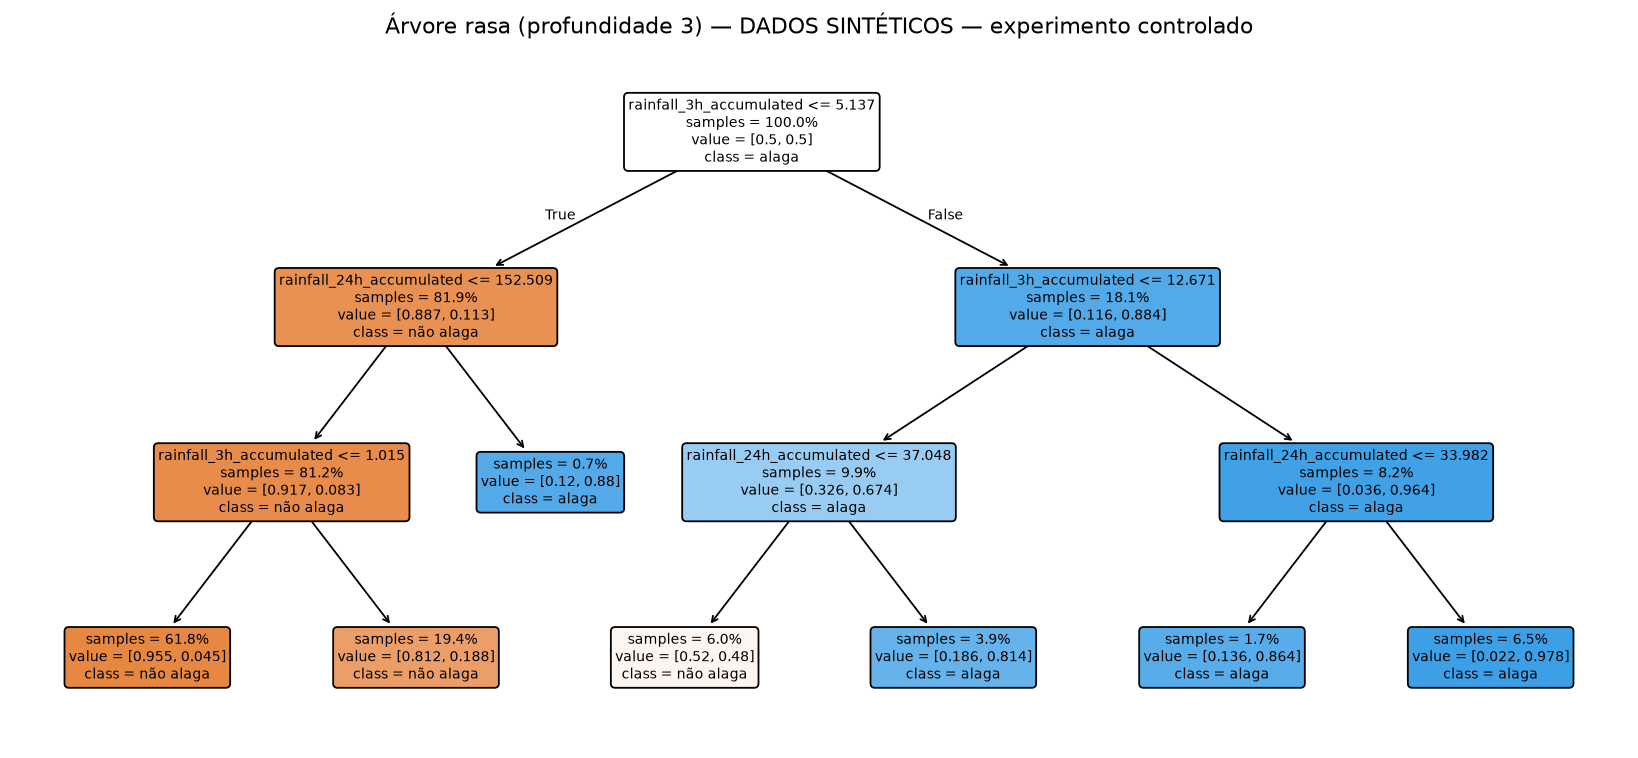

In [5]:
from mapi_ai import baselines
b = baselines.train(df)
fig("baseline_tree.png", 900)

## 4. Métricas no teste (usado uma vez)

**O quê:**
- precision, recall e F1 da classe positiva, ROC-AUC, **PR-AUC**, Brier, Brier skill score e ECE;
- matriz de confusão no limiar HIGH escolhido na validação;
- intervalo de confiança da diferença de PR-AUC por bootstrap **pareado**.

**Por quê:** com ~7% de positivos, o "nunca alaga" tem acurácia de ~93% e não serve para nada. É o **paradoxo da
acurácia**, visível na primeira linha da tabela.

In [6]:
from mapi_ai import evaluate
metrics = evaluate.run()
display(metrics[["modelo", "precision", "recall", "f1", "acuracia", "roc_auc", "pr_auc", "brier", "bss", "ece_10"]])
display(pd.read_csv(C.REPORTS_DIR / "significance.csv"))

AVISO: DADOS SINTÉTICOS — experimento controlado.
Rótulo gerado por fórmula conhecida (reports/synthetic_ground_truth.md) sobre horas reais.
Nenhuma métrica deste treino é desempenho em alagamento real.


== DADOS SINTÉTICOS — experimento controlado ==
           modelo  limiar_high_val  precision  recall     f1  acuracia  roc_auc  pr_auc  brier     bss  ece_10
      nunca_alaga           0.5000     0.0000  0.0000 0.0000     0.937   0.5000  0.0630 0.0594  0.0000  0.0203
regra_chuva3h>9mm           0.5000     0.5949  0.7460 0.6620     0.952   0.8559  0.4598 0.0480  0.1925  0.0480
        logistica           0.4582     0.5051  0.7937 0.6173     0.938   0.9285  0.7998 0.0489  0.1775  0.1132
      arvore_rasa           0.4798     0.3741  0.8254 0.5149     0.902   0.9255  0.6703 0.0567  0.0456  0.1097
           xgb_v2           0.2441     0.4261  0.7778 0.5506     0.920   0.9228  0.7644 0.0367  0.3830  0.0444
 xgb_v2_sem_local           0.4901     0.4804  0.7778 0.5939     0.933   0.9341  0.7923 0.0487  0.1813  0.0965
 xgb_v2_reanalise           0.3727     0.1389  0.7143 0.2326     0.703   0.7972  0.3184 0.1502 -1.5259  0.2591
 xgb_v2_calibrado           0.0506     0.4261  0.7778 0.5506    

,modelo,precision,recall,f1,acuracia,roc_auc,pr_auc,brier,bss,ece_10
0,nunca_alaga,0.0000,0.0000,0.0000,0.937,0.5000,0.0630,0.0594,0.0000,0.0203
1,regra_chuva3h>9mm,0.5949,0.7460,0.6620,0.952,0.8559,0.4598,0.0480,0.1925,0.0480
2,logistica,0.5051,0.7937,0.6173,0.938,0.9285,0.7998,0.0489,0.1775,0.1132
3,arvore_rasa,0.3741,0.8254,0.5149,0.902,0.9255,0.6703,0.0567,0.0456,0.1097
4,xgb_v2,0.4261,0.7778,0.5506,0.920,0.9228,0.7644,0.0367,0.3830,0.0444
5,xgb_v2_sem_local,0.4804,0.7778,0.5939,0.933,0.9341,0.7923,0.0487,0.1813,0.0965
6,xgb_v2_reanalise,0.1389,0.7143,0.2326,0.703,0.7972,0.3184,0.1502,-1.5259,0.2591
7,xgb_v2_calibrado,0.4261,0.7778,0.5506,0.920,0.9228,0.7644,0.0263,0.5575,0.0131


,a,b,delta_pr_auc,ic95_lo,ic95_hi,significativo
0,xgb_v2,logistica,-0.0354,-0.0695,-0.0057,True
1,xgb_v2,arvore_rasa,0.0942,0.0279,0.1600,True
2,xgb_v2,xgb_v2_reanalise,0.4461,0.3358,0.5476,True
3,xgb_v2,xgb_v2_sem_local,-0.0278,-0.0609,-0.0040,True
4,logistica,arvore_rasa,0.1296,0.0597,0.1943,True


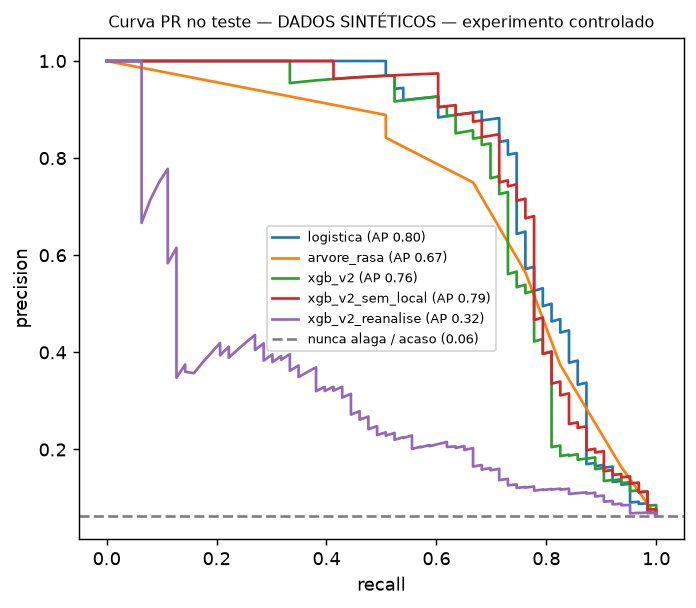

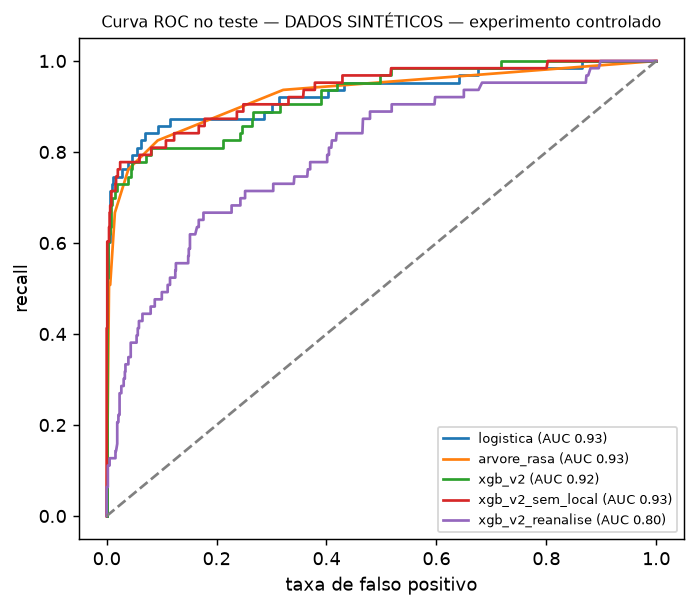

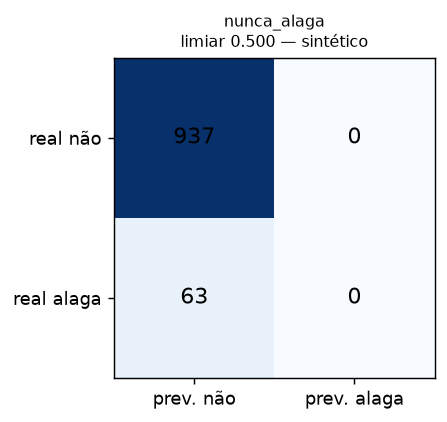

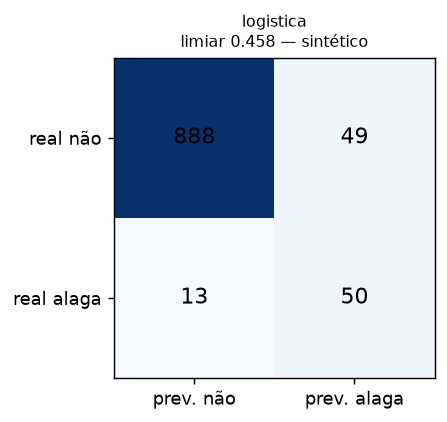

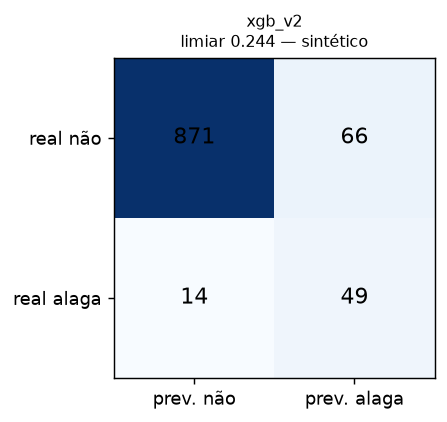

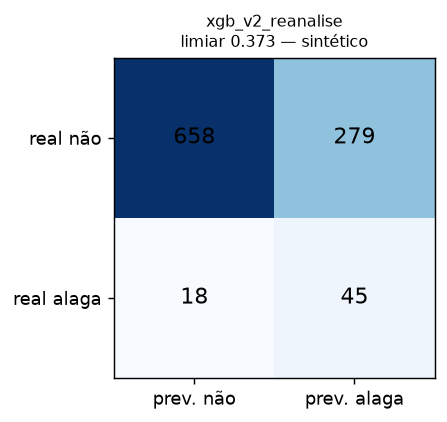

In [7]:
fig("pr_curve.png"); fig("roc_curve.png")
for n in ["nunca_alaga", "logistica", "xgb_v2", "xgb_v2_reanalise"]:
    fig(f"confusion_{n}.png", 300)

**Leitura:**
- **Caixa-preta:** a logística vence o XGBoost em PR-AUC, e o intervalo de confiança não cruza o zero. Neste
  experimento o XGBoost **não** se justifica, o que é coerente com o fato de a fórmula geradora ser logística.
- **Ablação Cemaden × reanálise:** a chuva medida dá muito mais PR-AUC. Ressalva honesta: o rótulo foi gerado a
  partir da chuva medida, então a ablação mede quanta informação sobre a chuva do local a reanálise preserva, e favorece
  o Cemaden por construção.
- **Sem latitude/longitude:** o modelo não perde nada, então o local era ruído.

## 5. Calibração e limiares LOW/MEDIUM/HIGH

**O quê:**
- **Calibração:** Platt na validação (`FrozenEstimator`, equivalente ao antigo `cv="prefit"`). O critério, fixado antes
  do teste, era usar o calibrador se a ECE de validação passasse de 0,05.
- **Limiares**, também escolhidos na validação:
  - HIGH: maior limiar com recall ≥ 0,80, porque perder um alagamento é pior que um alarme falso;
  - MEDIUM: recall ≥ 0,95, um nível de atenção.

**Por quê:** a faixa de risco só faz sentido se a probabilidade for calibrada; os cortes antigos (0,5 e 0,8) não tinham
justificativa.

{
 "method": "sigmoid (Platt)",
 "fit_on": "validation",
 "val_ece_raw": 0.04725559589639307,
 "val_ece_calibrated": 0.024024246732862863,
 "used": false
}
{
 "medium": 0.0159,
 "high": 0.2441,
 "criteria": {
  "high": "maior limiar com recall >= 0.8 na validação (melhor precisão)",
  "medium": "maior limiar com recall >= 0.95 na validação: nível de atenção, aceita mais alarmes falsos para quase não perder alagamento"
 },
 "validation": {
  "high": {
   "recall": 0.8333333333333334,
   "precision": 0.4580152671755725
  },
  "medium": {
   "recall": 0.9583333333333334,
   "precision": 0.1326923076923077
  }
 },
 "chosen_on": "validation",
 "probabilities": "raw"
}


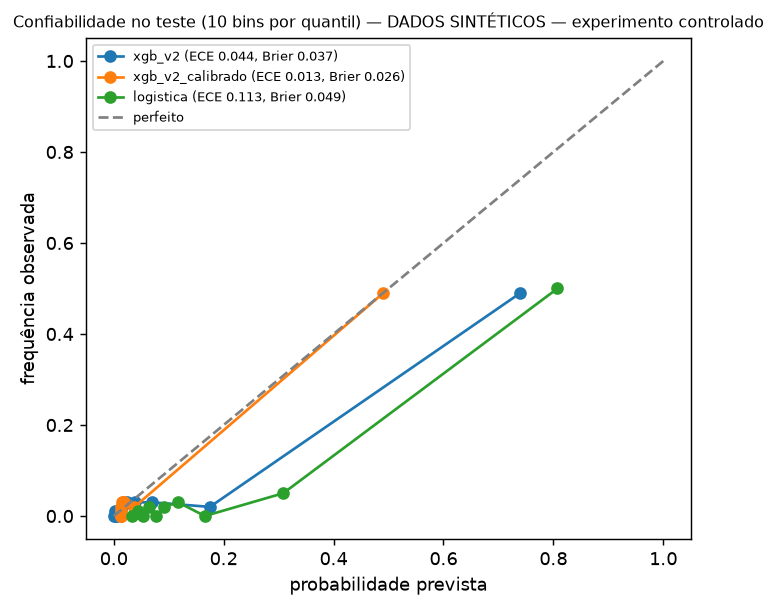

In [8]:
m = json.loads((C.MODELS_DIR / "metadata.json").read_text())
print(json.dumps(m["calibration"], indent=1)); print(json.dumps(m["thresholds"], indent=1, ensure_ascii=False))
fig("calibration.png")

## 6. SHAP

**Log-odds × probabilidade:** o XGBoost soma árvores em log-odds. Um "+1" em log-odds vale poucos pontos percentuais
perto de 1% e muitos perto de 50%. Por isso explicamos direto a **probabilidade** (`model_output="probability"`). Isso
exige `feature_perturbation="interventional"` e um fundo de 200 linhas do treino. A aditividade (base + Σ contribuições
= probabilidade) é verificada com `assert`.

AVISO: DADOS SINTÉTICOS — experimento controlado.
Rótulo gerado por fórmula conhecida (reports/synthetic_ground_truth.md) sobre horas reais.
Nenhuma métrica deste treino é desempenho em alagamento real.


/home/lucas/Documents/Projetos/MAPI/projeto-mapi-ai/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:00<00:00,  2.28it/s]

100%|██████████| 1/1 [00:00<00:00,  2.27it/s]

Top 5 global: [('rainfall_3h_accumulated', 0.0921), ('rainfall_24h_accumulated', 0.04685), ('current_rainfall', 0.01999), ('tide_level', 0.01423), ('rainfall_12h_accumulated', 0.01328)]


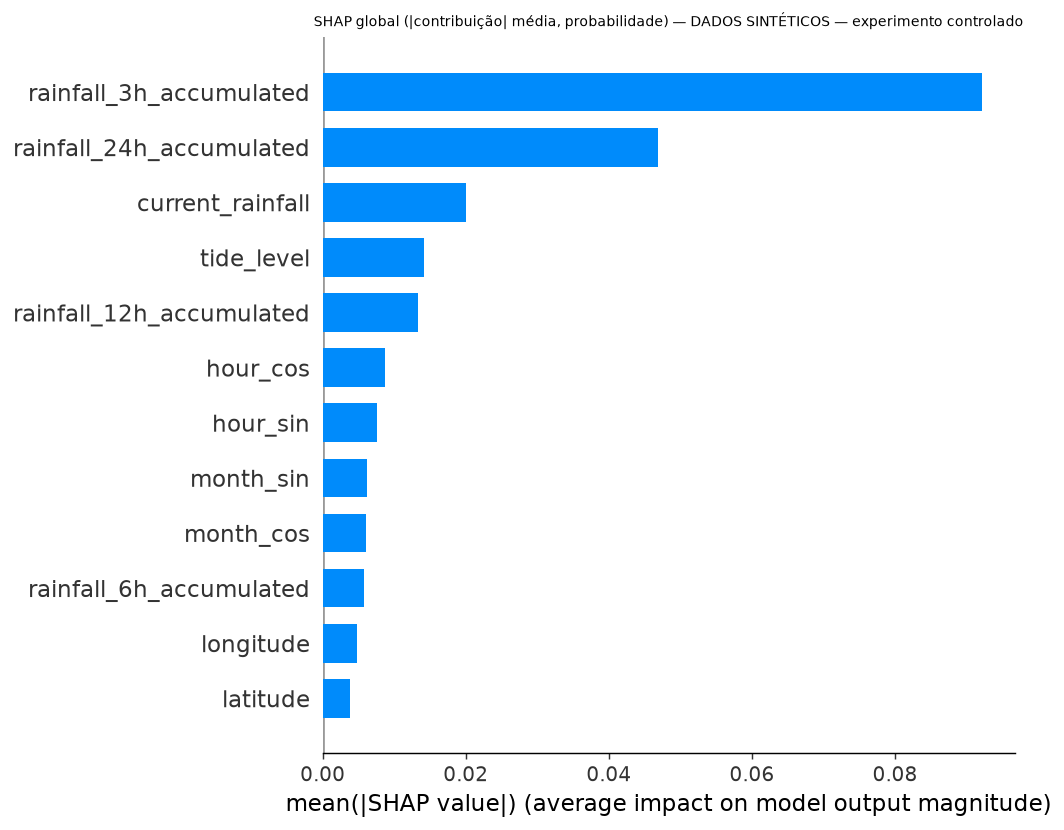

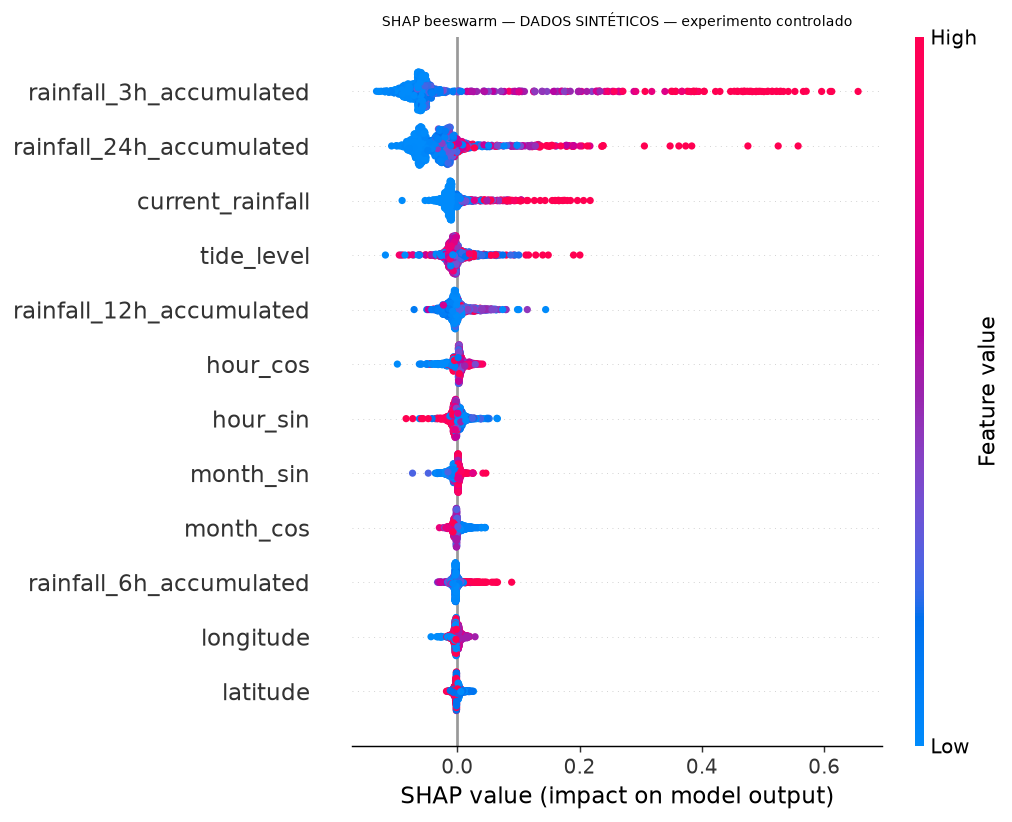

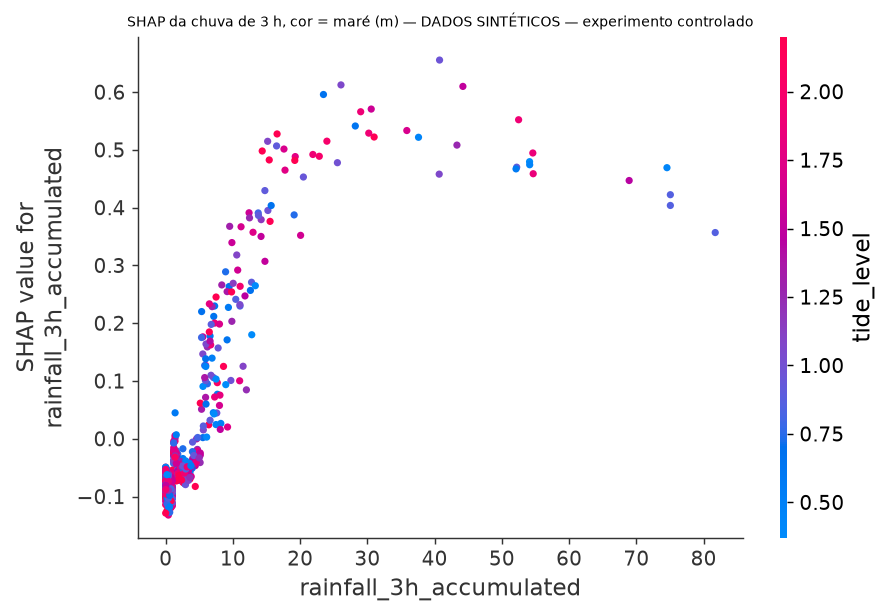

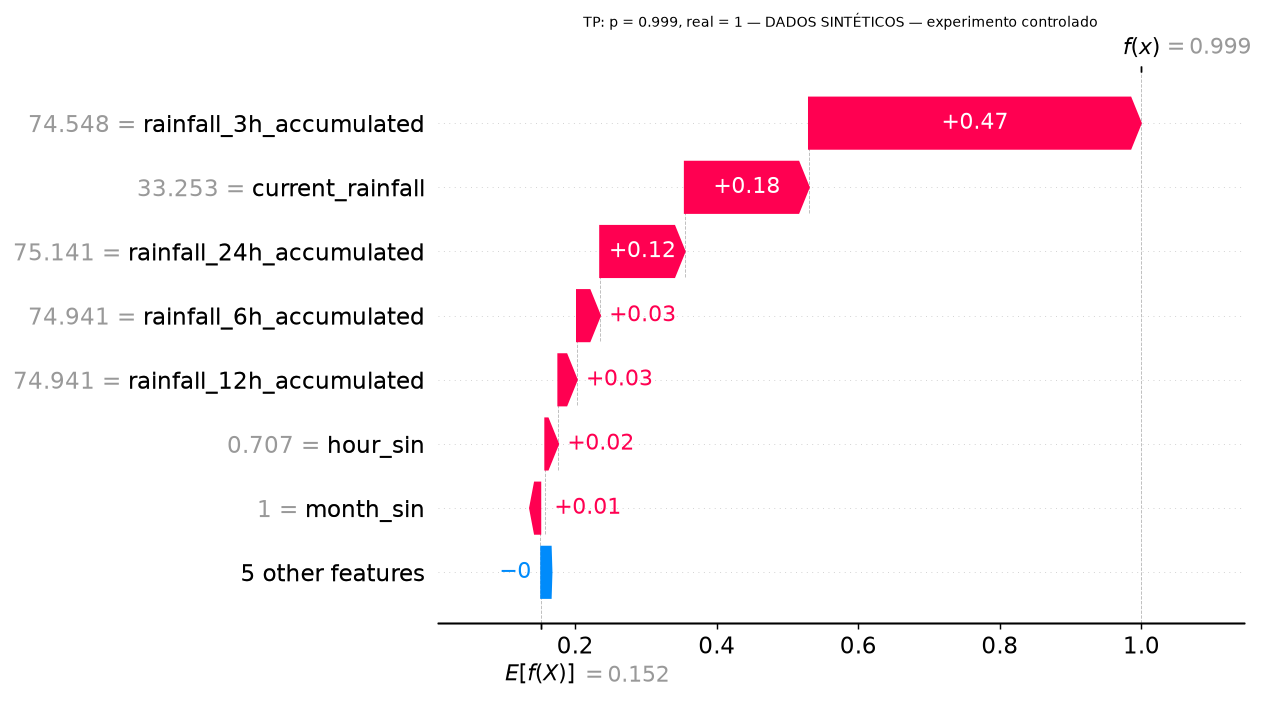

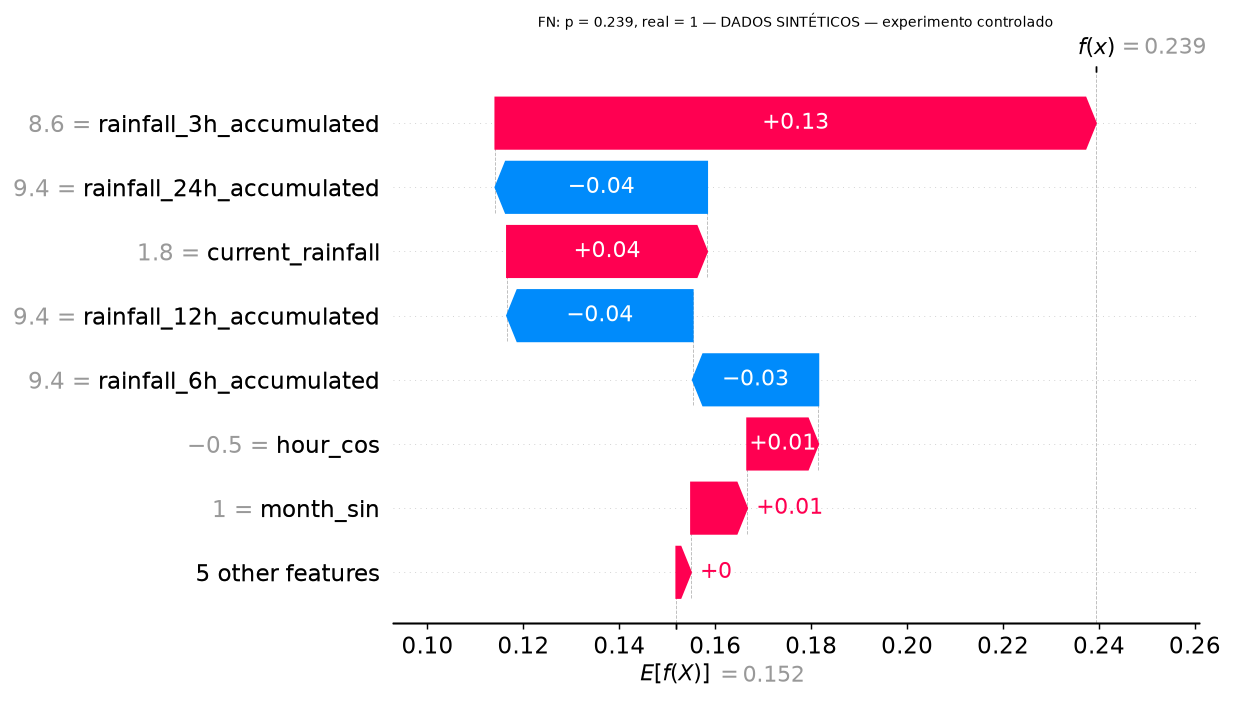

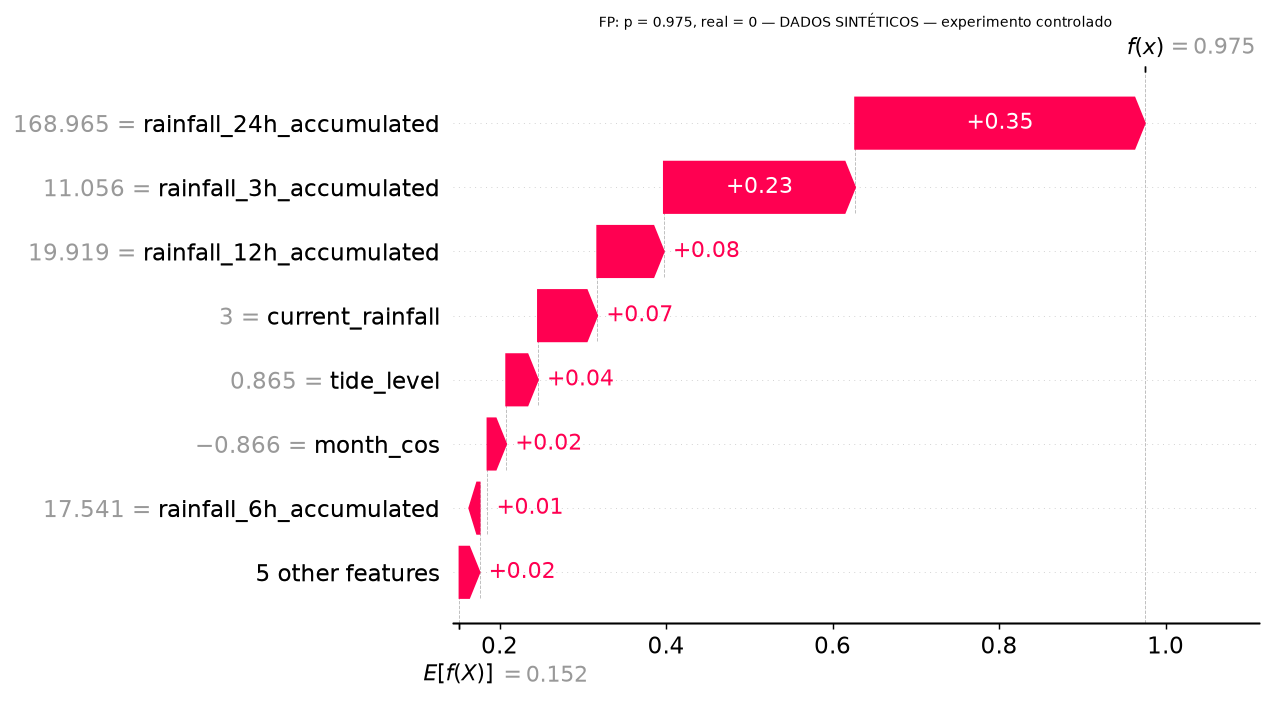

In [9]:
from mapi_ai.xai import run_all
xai = run_all.run()
print("Top 5 global:", list(xai["global_shap_mean_abs"].items())[:5])
fig("xai_shap_bar.png"); fig("xai_shap_beeswarm.png"); fig("xai_shap_dependence_rain3h_tide.png")
for k in ["TP", "FN", "FP"]:
    fig(f"xai_shap_waterfall_{k}.png")

## 7. LIME

Um modelo linear local, ajustado a perturbações de cada caso, em unidades originais e com `discretize_continuous=True`.
São os mesmos três casos: verdadeiro positivo, falso negativo e falso positivo.

TP [('rainfall_3h_accumulated > 2.99', 0.40369), ('rainfall_24h_accumulated > 31.62', 0.11046), ('current_rainfall > 0.60', 0.05507), ('rainfall_12h_accumulated > 15.72', -0.0188), ('month_sin > 0.87', 0.01369), ('-0.71 < hour_cos <= -0.00', 0.01293)]


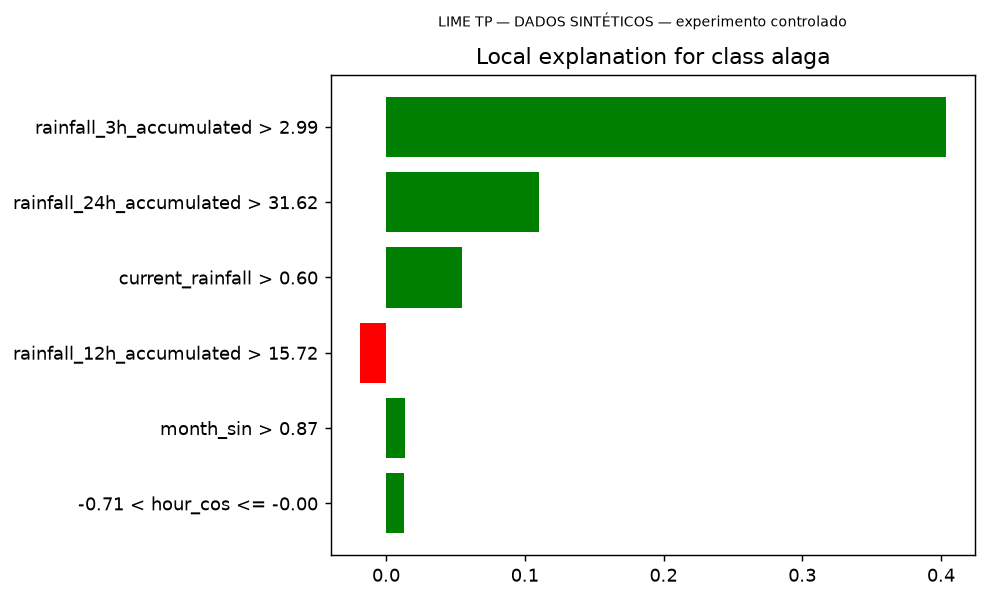

FN [('rainfall_3h_accumulated > 2.99', 0.38373), ('current_rainfall > 0.60', 0.03775), ('4.34 < rainfall_12h_accumulated <= 15.72', -0.02194), ('rainfall_6h_accumulated > 7.50', 0.01311), ('2.20 < rainfall_24h_accumulated <= 10.99', -0.01081), ('longitude <= -34.95', -0.01067)]


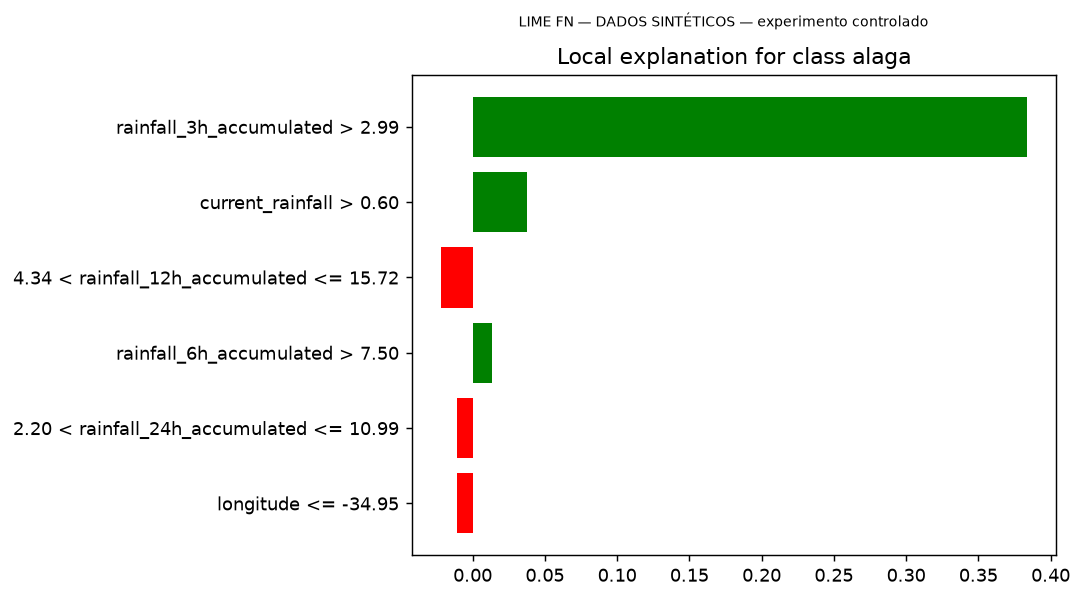

FP [('rainfall_3h_accumulated > 2.99', 0.36676), ('rainfall_24h_accumulated > 31.62', 0.11717), ('current_rainfall > 0.60', 0.04178), ('-0.71 < hour_cos <= -0.00', 0.01122), ('rainfall_6h_accumulated > 7.50', 0.01041), ('-0.50 < month_sin <= 0.50', 0.01015)]


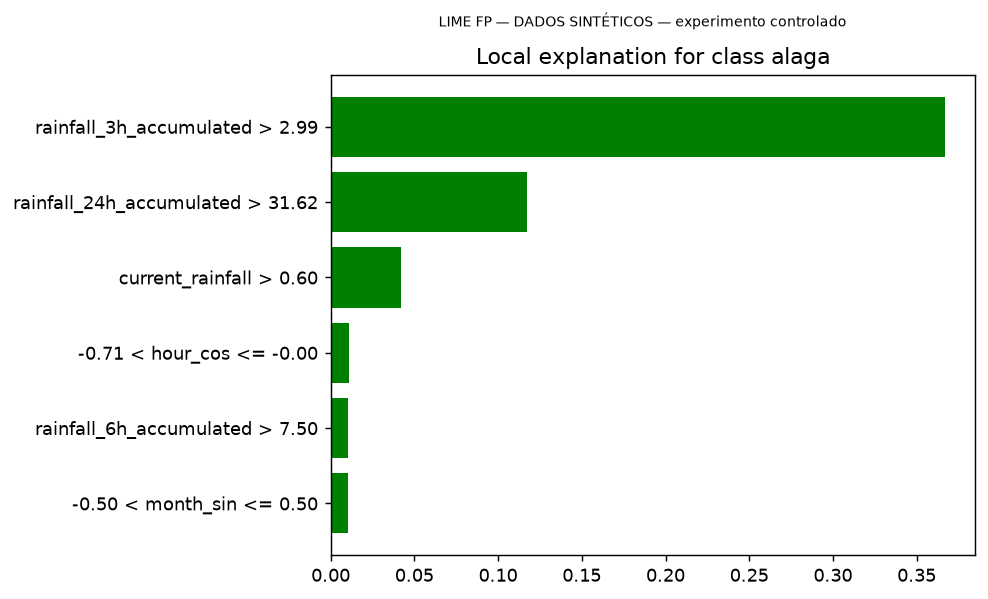

In [10]:
for k in ["TP", "FN", "FP"]:
    print(k, [(r["rule"], r["weight"]) for r in xai["cases"][k]["lime"]["rules"]])
    fig(f"xai_lime_{k}.png", 520)

## 8. Contrafactual (DiCE e escala)

**O quê:** para o verdadeiro positivo, quanto **menos** chuva levaria o risco a LOW? Variamos só a chuva; local, maré e
hora ficam fixos.

**Leitura:** é um **limiar** ("com X mm a menos em 3 h, o risco seria LOW"), não uma ação, porque chuva e maré não se
controlam. A DiCE sorteia cada janela de chuva independentemente; os candidatos passam por um reparo de coerência
(chuva de 1 h ≤ 3 h ≤ … ≤ 24 h) antes de serem aceitos.

In [11]:
cf = xai["counterfactual_TP"]
print(cf["scale"]["statement"]); print(cf["scale_below_high"]["statement"])
for c in cf["dice"]:
    print(c)

Com 72.6 mm a menos em 3 h (de 74.5 para 2.0 mm, e a chuva das outras janelas reduzida na mesma proporção), o risco seria LOW.
Com 64.6 mm a menos em 3 h (de 74.5 para 10.0 mm, e a chuva das outras janelas reduzida na mesma proporção), o risco sairia de HIGH (MEDIUM).
{'features': {'current_rainfall': 0.4, 'rainfall_3h_accumulated': 1.0, 'rainfall_6h_accumulated': 1.0, 'rainfall_12h_accumulated': 1.0, 'rainfall_24h_accumulated': 1.0}, 'probability': 0.0034, 'mm_less_in_3h': 73.55, 'statement': 'Com 73.5 mm a menos em 3 h (e as demais janelas como na linha), o risco seria LOW.'}
{'features': {'current_rainfall': 0.4, 'rainfall_3h_accumulated': 0.9, 'rainfall_6h_accumulated': 0.9, 'rainfall_12h_accumulated': 0.9, 'rainfall_24h_accumulated': 0.9}, 'probability': 0.0034, 'mm_less_in_3h': 73.65, 'statement': 'Com 73.6 mm a menos em 3 h (e as demais janelas como na linha), o risco seria LOW.'}
{'features': {'current_rainfall': 0.2, 'rainfall_3h_accumulated': 0.4, 'rainfall_6h_accumulated': 0

## 9. Avaliação das explicações

Em 50 linhas do teste:
1. concordância SHAP × LIME (Jaccard do top-5 e Spearman);
2. estabilidade do LIME com 10 sementes;
3. fidelidade por deleção (trocar as k mais importantes pelo fundo deve derrubar a previsão mais que trocar k ao acaso);
4. **Plano B:** o ranking global contra a fórmula geradora.

AVISO: DADOS SINTÉTICOS — experimento controlado.
Rótulo gerado por fórmula conhecida (reports/synthetic_ground_truth.md) sobre horas reais.
Nenhuma métrica deste treino é desempenho em alagamento real.


,metrica,media,desvio,n
0,concordancia_jaccard_top5_shap_lime,0.5260,0.1755,50
1,concordancia_spearman_shap_lime,0.5322,0.2432,50
2,estabilidade_lime_jaccard_top5_10_sementes,0.6095,0.1042,50
3,delecao_queda_prob_SHAP_k1,0.1126,0.1487,50
4,delecao_queda_prob_SHAP_k2,0.1627,0.1677,50
5,delecao_queda_prob_SHAP_k3,0.1761,0.1726,50
6,delecao_queda_prob_SHAP_k4,0.1786,0.1752,50
7,delecao_queda_prob_SHAP_k5,0.1794,0.1732,50
8,delecao_queda_prob_LIME_k1,0.1044,0.1457,50
9,delecao_queda_prob_LIME_k2,0.1446,0.1747,50


Verdade: ['rainfall_3h_accumulated', 'rainfall_24h_accumulated', 'current_rainfall', 'tide_level']
SHAP:    ['rainfall_3h_accumulated', 'rainfall_24h_accumulated', 'current_rainfall', 'tide_level'] | Spearman 0.84
LIME:    ['rainfall_3h_accumulated', 'rainfall_24h_accumulated', 'current_rainfall', 'tide_level'] | Spearman 0.803


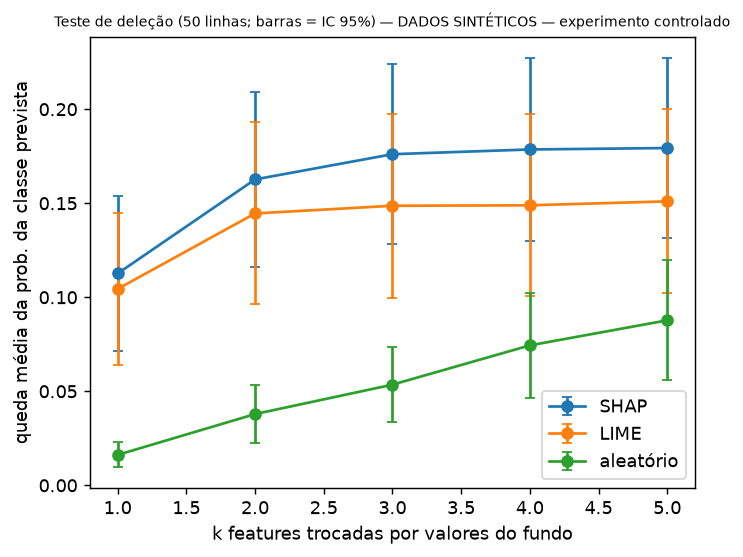

In [12]:
from mapi_ai.xai import evaluate_explanations
ev = evaluate_explanations.run()
display(pd.DataFrame(ev["table"]))
print("Verdade:", list(ev["plan_b"]["true_ranking"])[:4])
print("SHAP:   ", ev["plan_b"]["shap_order_of_true_features"], "| Spearman", round(ev["plan_b"]["spearman_shap_vs_truth"], 3))
print("LIME:   ", ev["plan_b"]["lime_order_of_true_features"], "| Spearman", round(ev["plan_b"]["spearman_lime_vs_truth"], 3))
fig("deletion_curve.png")

## 10. Limitações (em linguagem de slide)

- **Rótulo:** não há registro de alagamento com hora nem a 500 m dos pontos; tudo aqui é **sintético**.
- **A fórmula é logística:** isso favorece a regressão logística e explica a derrota do XGBoost.
- **Ablação da chuva:** o rótulo vem da chuva medida, então o ganho do Cemaden sobre a reanálise é, em parte,
  construído. Mede informação preservada, não previsão de alagamento real.
- **Features correlacionadas:** os acumulados de 1 a 24 h se sobrepõem; SHAP intervencional e LIME podem dividir o
  crédito entre eles (o LIME pôs a chuva de 12 h no lugar da maré).
- **Fonte da chuva:** treino com chuva medida, mas na inferência o backend ainda pode enviar outra fonte; a resposta
  declara `rain_source` do treino.
- **Calibração:** o critério pré-fixado não aplicou o Platt; no teste, o calibrado seria melhor (Brier 0,026 contra
  0,037). Fica como próximo passo, a decidir na validação.

DADOS DA REDE OBSERVACIONAL DO CEMADEN/MCTIC